# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-10_eng1 | generated: 2026-10-10T11:53:38 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"50,000원 → 50,000.00 USD (환율 1 USD = 1.00 KRW, 2026-10-09)"
월 적립,0원 (매월 25일) → 0.00 USD
투자기간,"5.0년, 시작 희망일 2026-10-09"
투자성향,aggressive · 손실 감내 수준 40% · 손실 시 buy_more
목표 수익률 / 비교지수,연 15% / SPY
전략 템플릿 / 기준 비중,momentum / market_cap
투자 아이디어,"에너지 전환 쪽에 공격적으로 투자하고 싶어요. 태양광·풍력 같은 재생에너지, 배터리·에너지저장장치, 전력망·변압기·전력기기, 원전 관련 ..."


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

재생에너지, 배터리·에너지저장, 전력망·전력기기, 원전 관련 미국 기업에 집중하는 테마형 투자입니다. 5년 보유를 전제로 하며, 최근 1년 모멘텀 스크린과 높은 변동성 수용 성향을 반영합니다.



,설명,GICS 코드,키워드
테마,,,
태양광·풍력 재생에너지,태양광 발전·태양전지·인버터·추적 장비를 공급하거나 풍력 발전 및 터빈·부품·설치 사업을 하는 기업을 포함합니다.,"55105010, 20104010, 20104020, 20103010, 45301020, 15101050","solar power, photovoltaic, solar inverter, solar module, wind turbine, wind ..."
배터리·에너지저장장치,"전기차·전력망 등에 쓰이는 배터리 셀과 소재를 생산하거나, 배터리 기반 에너지저장장치 및 저장 시스템을 공급하는 기업을 포함합니다.","20104010, 20106020, 15101050, 151040, 25101010, 45203015","battery cell, lithium-ion battery, battery energy storage, energy storage sy..."
전력망·변압기·전력기기,"송전·배전망의 구축·운영에 참여하거나 변압기, 스위치기어, 전력 제어·배전 장비 및 관련 엔지니어링 서비스를 제공하는 기업을 포함합니다.","20104010, 20104020, 20103010, 20106020, 55101010, 55103010, 45203015","power grid, electric grid, transformer, switchgear, power distribution, grid..."
원자력·원전 산업,"원자력 발전소를 운영하거나 원전 건설·정비, 원자로 및 원자력 설비·부품, 핵연료·우라늄 공급과 관련된 기업을 포함합니다.","55101010, 55103010, 20103010, 20104020, 20106020, 20101010, 151040","nuclear power, nuclear reactor, nuclear plant, uranium, nuclear fuel, reacto..."


,값
항목,
종목 수,목표 10 (허용 8~12)
종목당 상한,20%
섹터당 상한,60%
리밸런싱,1×1개월마다 리밸런싱
제외 테마,"tobacco, gambling"
변동성 선호 / 허용 MDD,high / 40%
해석 메모,손실 시 추가 매수 의향이 있고 자연어에서도 변동성을 감수한다고 밝혔으므로 높은 변동성 선호로 해석했습니다. 손실 반응은 buy_more...


,항목,확인한 점,처리
0,natural_language.idea / strategy_preference.template,"자연어는 최근 1년 주가 흐름이 강한 종목을 원하지만, momentum 템플릿의 지표는 최근 1개월을 제외한 12개월 수익률입니다.",명시된 momentum 템플릿에 따라 return_12m_1m을 사용합니다.
1,GICS 분류 트리 / nuclear_energy,제공된 GICS 트리에는 우라늄 채굴과 핵연료를 직접 나타내는 세부 코드가 없습니다.,"관련 검색 키워드를 사용하고, 상위 금속·광업 코드와 원전 관련 산업 코드를 넓게 포함해 후속 분류 단계에서 판별합니다."


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

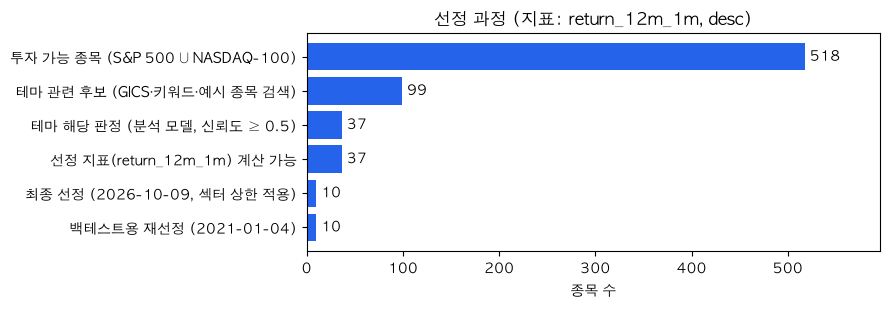

,회사,섹터,테마,신뢰도,순위(2021-01-04),지표(백테스트),순위(2026-10-09),지표(2026),테마 판정 사유
티커,,,,,,,,,
TSLA,"Tesla, Inc.",Consumer Discretionary,"batteries_energy_storage, renewable_energy",0.68,1.0,+542.09%,NaN,+nan%,배터리·Powerwall·Megapack을 공급하고 태양광 제품도 판매
GNRC,Generac,Industrials,"renewable_energy, batteries_energy_storage",0.65,2.0,+107.28%,NaN,+nan%,태양광 인버터와 주택용 배터리 저장 시스템을 공급
ALB,Albemarle Corporation,Materials,batteries_energy_storage,0.70,3.0,+91.65%,3.0,+34.25%,배터리 셀에 쓰이는 리튬 화합물을 생산·공급
PWR,Quanta Services,Industrials,power_grid_equipment,0.90,4.0,+68.45%,2.0,+39.61%,송전·배전망 건설과 전력 인프라 엔지니어링을 수행
FSLR,First Solar,Information Technology,renewable_energy,0.95,5.0,+58.70%,NaN,+nan%,태양광 모듈과 발전용 PV 솔루션을 제조·공급
ETN,Eaton Corporation,Industrials,power_grid_equipment,0.90,6.0,+29.06%,7.0,+9.52%,배전·전력 제어 장비와 전력 관리 솔루션을 공급
NEE,NextEra Energy,Utilities,"renewable_energy, power_grid_equipment, nuclear_energy",0.85,7.0,+26.23%,NaN,+nan%,대규모 풍력·태양광 발전과 전력망·원전을 운영
J,Jacobs Solutions,Industrials,"power_grid_equipment, nuclear_energy",0.60,8.0,+18.65%,NaN,+nan%,전력 인프라 엔지니어링과 원전 설계·정비 서비스를 수행
PCG,PG&E Corporation,Utilities,"power_grid_equipment, nuclear_energy",0.85,9.0,+18.45%,NaN,+nan%,전력망을 운영하고 디아블로캐니언 원전을 운영


백테스트 재선정에서 추가: ['FSLR', 'GNRC', 'J', 'NEE', 'PCG', 'TSLA', 'XEL'] | 빠짐: ['D', 'ED', 'EIX', 'ETR', 'GEV', 'HUBB', 'PNW']


,회사,제외 이유,지표값
티커,,,
EVRG,Evergy,rank_beyond_n,0.081771
AEP,American Electric Power,rank_beyond_n,0.077118
GNRC,Generac,rank_beyond_n,0.060351
AES,AES Corporation,rank_beyond_n,0.054882
AEE,Ameren,rank_beyond_n,0.040861
FE,FirstEnergy,rank_beyond_n,0.030526
LNT,Alliant Energy,rank_beyond_n,0.021726
CNP,CenterPoint Energy,rank_beyond_n,0.011375


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
TSLA,Consumer Discretionary,10.0%,20.0%
GNRC,Industrials,10.0%,4.2%
ALB,Materials,10.0%,5.7%
PWR,Industrials,10.0%,4.1%
FSLR,Information Technology,10.0%,4.1%
ETN,Industrials,10.0%,14.6%
NEE,Utilities,10.0%,20.0%
J,Industrials,10.0%,4.1%
PCG,Utilities,10.0%,10.3%
XEL,Utilities,10.0%,12.9%


적용된 제약: ['min_weight:PWR', 'min_weight:FSLR', 'min_weight:J', 'stock_cap:TSLA', 'stock_cap:NEE'] | 섹터 비중: {'Consumer Discretionary': 0.2, 'Industrials': 0.269, 'Materials': 0.057, 'Information Technology': 0.041, 'Utilities': 0.433}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,27.5%,10.0,10.0%
시가총액비중,시가총액에 비례한 비중 (지수 방식),28.3%,7.2,20.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),25.3%,9.2,14.2%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),23.8%,6.4,20.0%


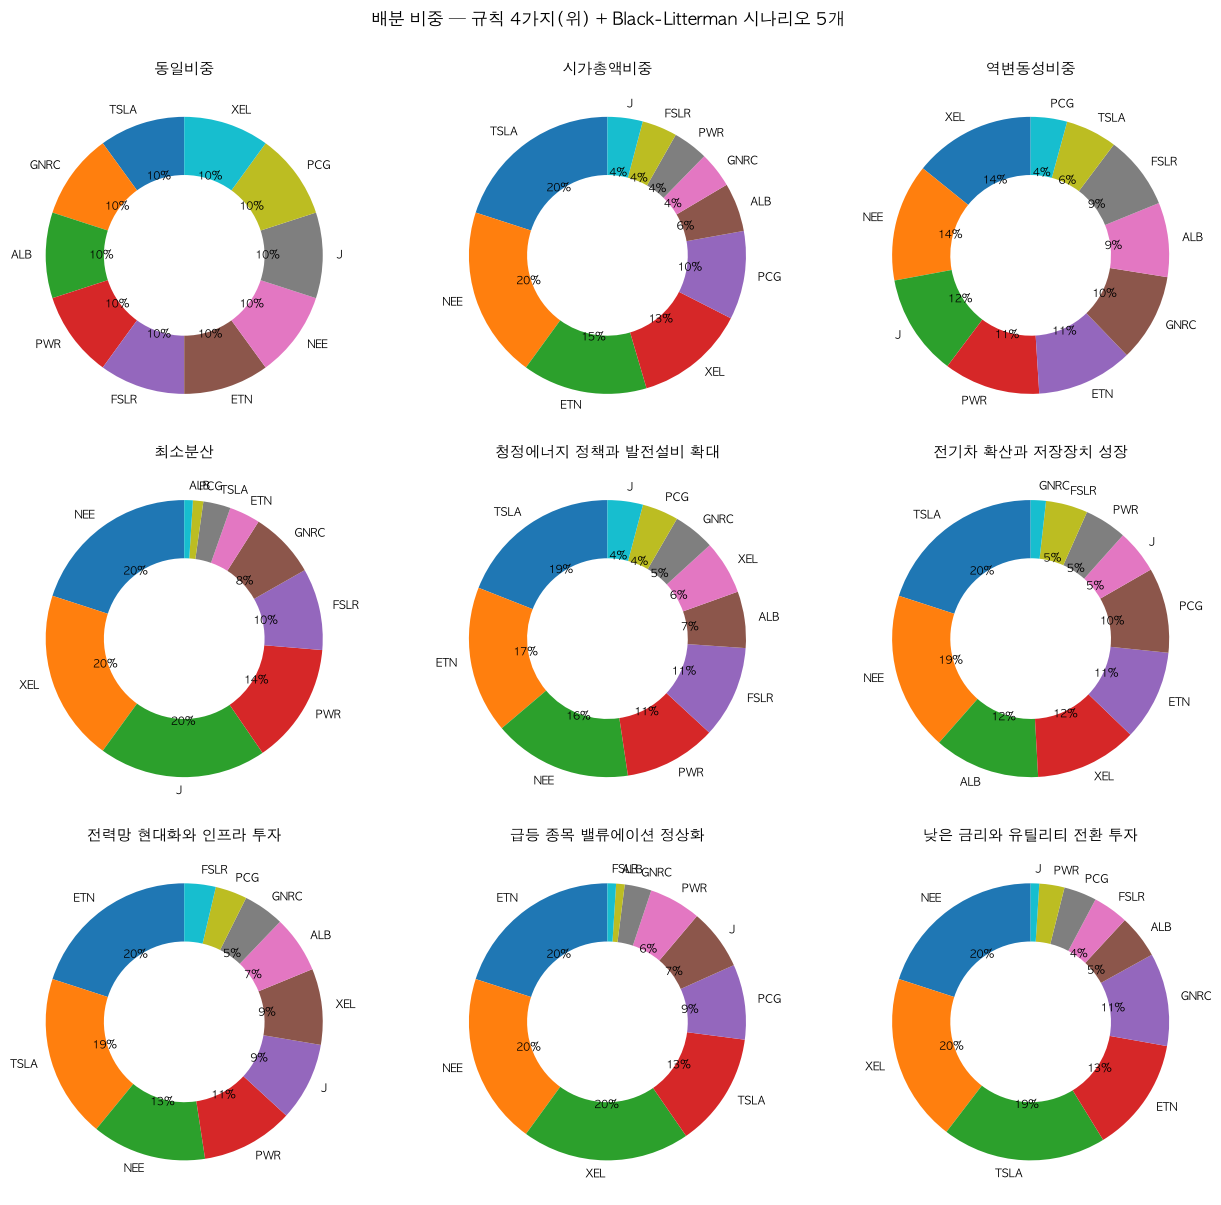

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
청정에너지 정책과 발전설비 확대,"정권 교체와 기후정책 강화 기대가 재생에너지 프로젝트의 파이프라인과 발주를 뒷받침하는 시나리오입니다. 태양광 공급업체와 송전·배전 시공사의 성장 기회를 높게 보되, 규제형 전력사보다 설비 투자 수혜주에 무게를 둡니다.",[절대] FSLR +13%/년 (신뢰 0.45) / [절대] PWR +12%/년 (신뢰 0.46) / [상대] FSLR+PWR > XEL +8%/년 (신뢰 0.40) / [상대] NEE > PCG +7%/년 (신뢰 0.34),+6.7%,10.8%,28.5%
전기차 확산과 저장장치 성장,"전기차 보급 확대와 배터리 저장장치의 경제성 개선이 이어지는 시나리오입니다. 배터리 수요 증가에 따른 Tesla와 리튬 공급업체의 성장 가능성을 반영하되, 경쟁 심화와 높은 기대치 때문에 확신은 제한합니다.",[절대] TSLA +21%/년 (신뢰 0.32) / [절대] ALB +14%/년 (신뢰 0.38) / [상대] TSLA+ALB > GNRC +9%/년 (신뢰 0.31) / [상대] ALB > ETN +6%/년 (신뢰 0.30),+6.7%,11.0%,29.1%
전력망 현대화와 인프라 투자,"재생에너지 접속, 노후 설비 교체, 전력 수요 증가가 송배전망 투자를 촉진하는 시나리오입니다. 프로젝트 수행 역량과 전력관리 장비 공급망을 가진 기업을 선호하며, 단기 실적 변동이 큰 발전사업자보다 인프라 공급망에 초점을 둡니다.",[절대] ETN +12%/년 (신뢰 0.43) / [절대] J +9%/년 (신뢰 0.36) / [상대] PWR+ETN > PCG +10%/년 (신뢰 0.39) / [상대] PWR > NEE +6%/년 (신뢰 0.34),+6.7%,10.2%,28.3%
급등 종목 밸류에이션 정상화,최근 급등으로 높아진 성장 기대가 실적과 밸류에이션 검증을 받는 시나리오입니다. 장기 테마는 유지하되 단기적으로는 변동성이 큰 모멘텀 종목보다 수익 기반이 상대적으로 안정적인 전력·산업재 기업을 선호합니다.,[절대] TSLA +8%/년 (신뢰 0.27) / [절대] PCG +10%/년 (신뢰 0.22) / [상대] NEE+XEL > TSLA +8%/년 (신뢰 0.35) / [상대] ETN > ALB+FSLR +7%/년 (신뢰 0.32),+6.7%,8.0%,26.7%
낮은 금리와 유틸리티 전환 투자,"낮은 금리가 유지되고 유틸리티의 재생에너지·전력망 투자가 이어지는 시나리오입니다. 자본집약적 사업의 조달 여건 개선을 긍정적으로 보면서도, 재무·규제 불확실성이 큰 기업보다는 투자 계획과 수익 기반이 비교적 안정적인 전력사를 선호합니다.",[절대] NEE +7%/년 (신뢰 0.38) / [절대] XEL +6%/년 (신뢰 0.36) / [상대] NEE+XEL > PCG +9%/년 (신뢰 0.34) / [상대] GNRC > J +6%/년 (신뢰 0.30),+6.7%,9.0%,27.3%


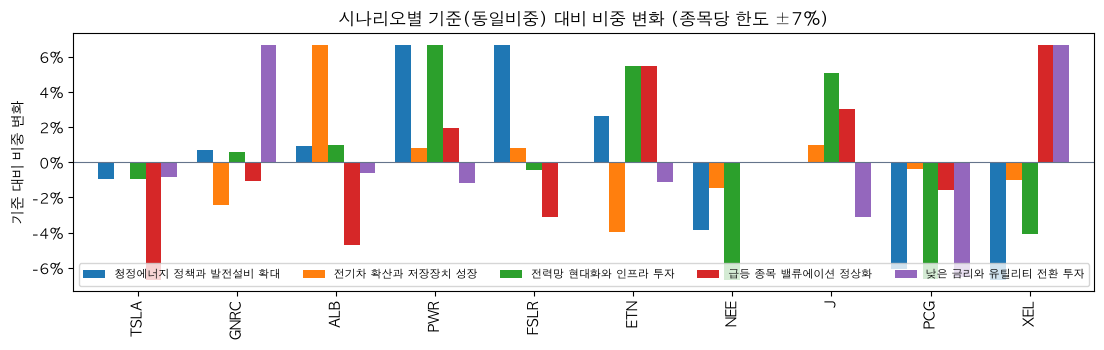

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2021-01-04~2026-10-09 (1449거래일) · 적립 0회 × 0 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: bl_03 (추천)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: 청정에너지 정책과 발전설비 확대,black_litterman,+175.8%,+19.3%,25.3%,0.61,-31.6%,+4.0%,"137,820","50,000",+19.2%,75%
시나리오: 전기차 확산과 저장장치 성장,black_litterman,+116.2%,+14.4%,23.8%,0.43,-29.9%,-0.9%,"108,027","50,000",+14.3%,100%
시나리오: 전력망 현대화와 인프라 투자,black_litterman,+177.1%,+19.4%,24.2%,0.64,-30.5%,+4.1%,"138,504","50,000",+19.3%,100%
시나리오: 급등 종목 밸류에이션 정상화,black_litterman,+137.8%,+16.3%,19.9%,0.62,-23.6%,+1.0%,"118,823","50,000",+16.2%,50%
시나리오: 낮은 금리와 유틸리티 전환 투자,black_litterman,+118.0%,+14.5%,23.4%,0.45,-28.1%,-0.8%,"108,950","50,000",+14.5%,100%
동일비중,template,+139.7%,+16.4%,23.5%,0.53,-30.5%,+1.1%,"119,777","50,000",+16.4%,–
시가총액비중,template,+125.7%,+15.2%,22.8%,0.49,-28.3%,-0.1%,"112,813","50,000",+15.2%,–
역변동성비중,template,+142.8%,+16.7%,22.3%,0.57,-28.9%,+1.4%,"121,354","50,000",+16.6%,–
최소분산,template,+141.6%,+16.6%,20.1%,0.63,-23.8%,+1.3%,"120,740","50,000",+16.5%,–


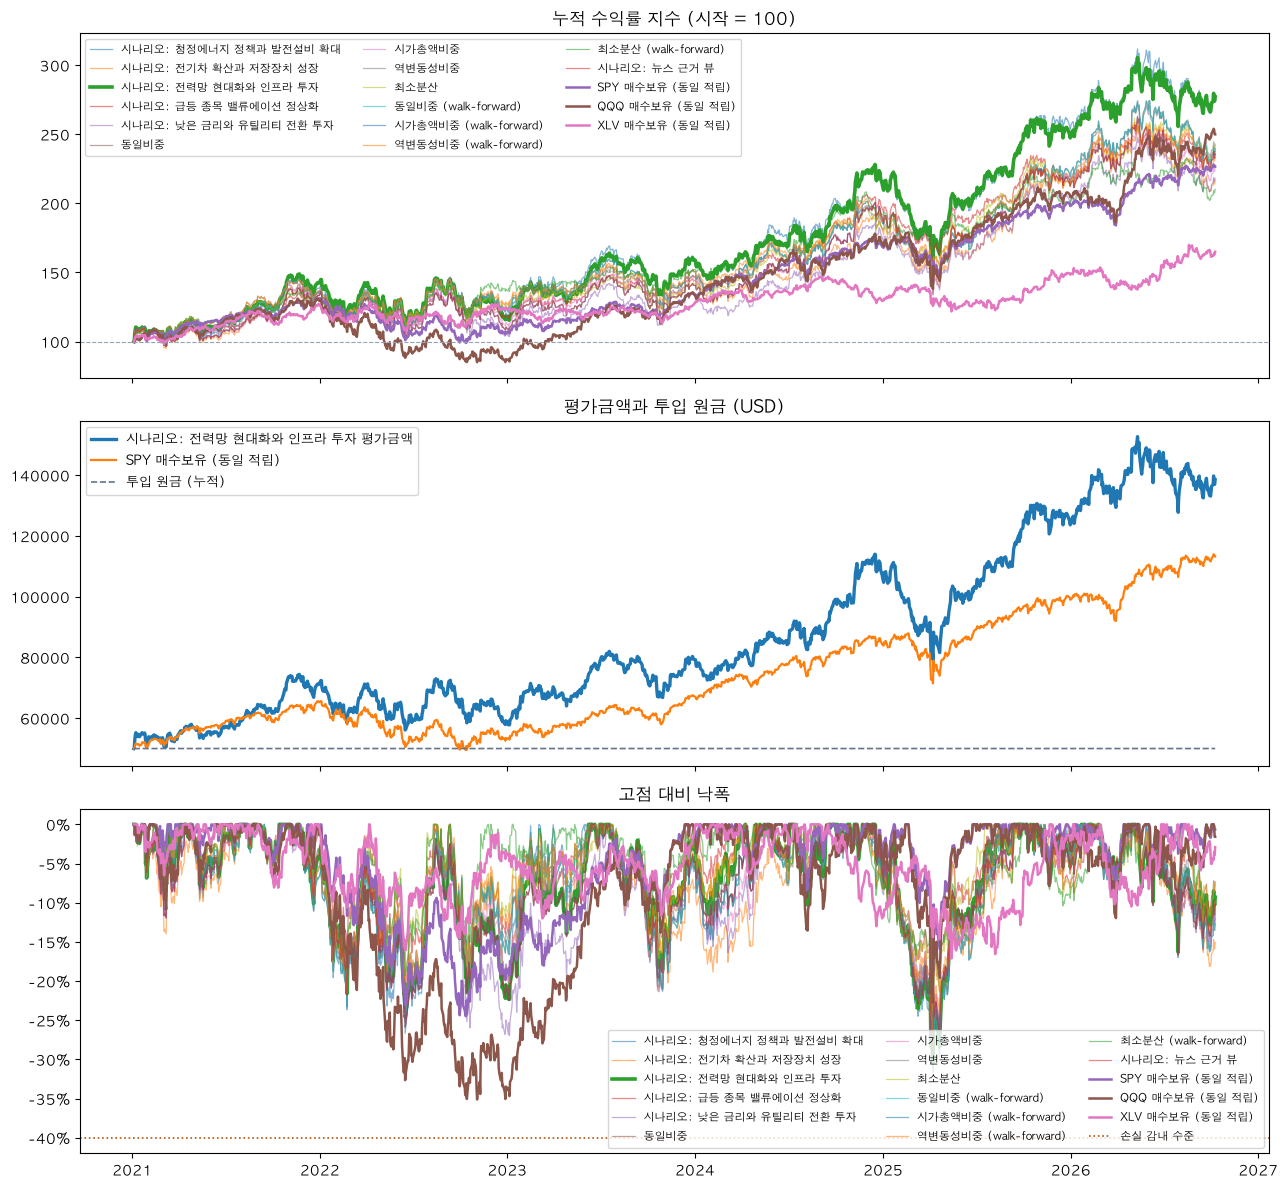

시나리오: 전력망 현대화와 인프라 투자 최대낙폭 -30.5%: 고점 2024-12-16 → 저점 2025-04-08 → 회복 2025-09-12 (고점 아래 270일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2021,2022,2023,2024,2025,2026
시나리오: 전력망 현대화와 인프라 투자,+42.5%,-17.1%,+34.5%,+33.8%,+16.4%,+12.0%
SPY 매수보유 (동일 적립),+30.5%,-18.2%,+26.2%,+24.9%,+17.7%,+14.4%
시가총액비중,+34.5%,-15.7%,+27.0%,+31.1%,+14.4%,+4.5%


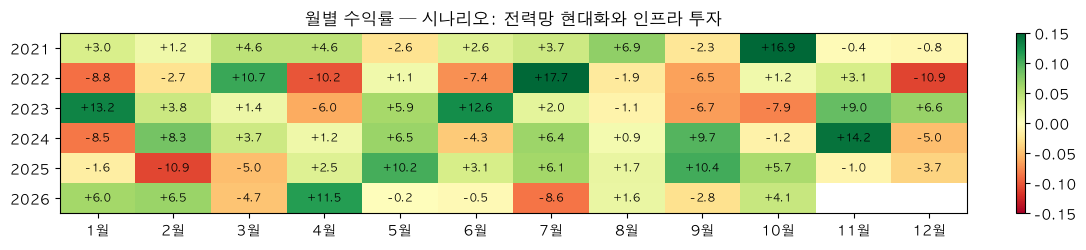

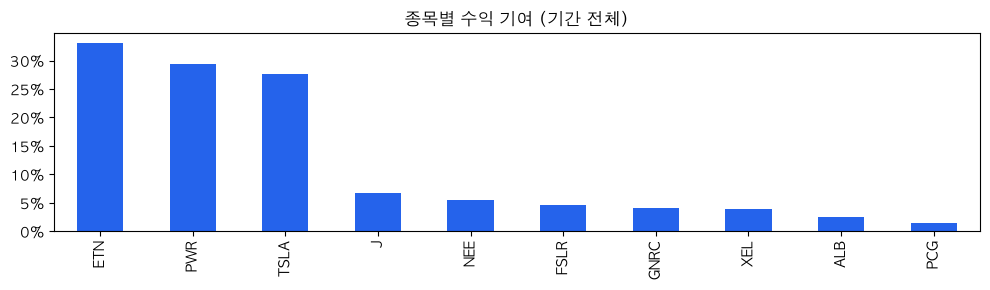

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,TSLA,GNRC,ALB,PWR,FSLR,ETN,NEE,J,PCG,XEL
2021-01-04,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-02-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-03-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-04-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-05-03,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-06-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-07-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-08-02,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-09-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%
2021-10-01,19.1%,4.8%,6.6%,10.8%,3.7%,20.0%,13.3%,9.2%,3.7%,8.9%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2021-01-04,rebalance,"49,975","50,000",–,–,–,,,–,–,–,10,24.99
2021-02-01,rebalance,"52,876","50,000",+5.8%,+2.0%,-6.8%,GNRC +15.2%,PCG -5.9%,+111.3%,-6.8%,3.23,10,1.55
2021-03-01,rebalance,"53,577","50,000",+1.3%,+3.5%,-4.4%,GNRC +33.8%,TSLA -14.5%,+58.7%,-6.8%,1.98,10,3.30
2021-04-01,rebalance,"54,668","50,000",+2.0%,+3.2%,-5.6%,XEL +13.8%,TSLA -7.9%,+44.9%,-8.5%,1.53,10,1.52
2021-05-03,rebalance,"56,735","50,000",+3.8%,+4.4%,-2.1%,ALB +10.1%,FSLR -12.0%,+47.7%,-8.5%,1.81,10,0.74
2021-06-01,rebalance,"55,559","50,000",-2.1%,+0.4%,-6.0%,J +5.0%,PCG -11.2%,+29.9%,-8.5%,1.12,10,1.20
2021-07-01,rebalance,"57,336","50,000",+3.2%,+2.9%,-2.7%,GNRC +28.5%,PWR -5.8%,+32.2%,-8.5%,1.30,10,1.54
2021-08-02,rebalance,"59,155","50,000",+3.2%,+1.7%,-3.8%,ALB +20.3%,PCG -13.4%,+34.1%,-8.5%,1.44,10,1.17
2021-09-01,rebalance,"63,190","50,000",+6.8%,+3.2%,-3.0%,ALB +15.6%,J +0.6%,+42.5%,-8.5%,1.92,10,1.08


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: 청정에너지 정책과 발전설비 확대,absolute,[절대] FSLR +13%/년 (신뢰 0.45),+13%,-13.8%,빗나감
1,시나리오: 청정에너지 정책과 발전설비 확대,absolute,[절대] PWR +12%/년 (신뢰 0.46),+12%,+70.6%,적중
2,시나리오: 청정에너지 정책과 발전설비 확대,relative,[상대] FSLR+PWR > XEL +8%/년 (신뢰 0.40),+8%,+21.3%,적중
3,시나리오: 청정에너지 정책과 발전설비 확대,relative,[상대] NEE > PCG +7%/년 (신뢰 0.34),+7%,+22.7%,적중
4,시나리오: 전기차 확산과 저장장치 성장,absolute,[절대] TSLA +21%/년 (신뢰 0.32),+21%,+57.5%,적중
5,시나리오: 전기차 확산과 저장장치 성장,absolute,[절대] ALB +14%/년 (신뢰 0.38),+14%,+60.2%,적중
6,시나리오: 전기차 확산과 저장장치 성장,relative,[상대] TSLA+ALB > GNRC +9%/년 (신뢰 0.31),+9%,+11.0%,적중
7,시나리오: 전기차 확산과 저장장치 성장,relative,[상대] ALB > ETN +6%/년 (신뢰 0.30),+6%,+13.0%,적중
8,시나리오: 전력망 현대화와 인프라 투자,absolute,[절대] ETN +12%/년 (신뢰 0.43),+12%,+47.3%,적중
9,시나리오: 전력망 현대화와 인프라 투자,absolute,[절대] J +9%/년 (신뢰 0.36),+9%,+35.2%,적중


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.4, 'target_annual_return': 0.15, 'benchmark': 'SPY', 'volatility_preference': 'high', 'max_weight_per_stock': 0.2, 'max_weight_per_sector': 0.6, 'min_holdings': 8}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: 청정에너지 정책과 발전설비 확대,pass,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 전기차 확산과 저장장치 성장,pass,warn,warn,pass,warn,pass,pass,pass,pass,pass
시나리오: 전력망 현대화와 인프라 투자,pass,pass,pass,pass,warn,pass,pass,pass,pass,pass
시나리오: 급등 종목 밸류에이션 정상화,pass,pass,pass,pass,pass,pass,pass,pass,pass,pass
시나리오: 낮은 금리와 유틸리티 전환 투자,pass,warn,warn,pass,warn,pass,pass,pass,pass,pass
동일비중,pass,pass,pass,pass,pass,pass,pass,pass,pass,pass
시가총액비중,pass,pass,warn,pass,warn,pass,pass,pass,pass,pass
역변동성비중,pass,pass,pass,pass,pass,pass,pass,pass,pass,pass
최소분산,pass,pass,pass,pass,pass,pass,pass,pass,pass,pass
동일비중 (walk-forward),pass,pass,pass,pass,pass,pass,pass,pass,pass,pass


요약: {'n_pass': 6, 'n_warn': 8, 'n_fail': 0}
추천: bl_03 — 검증 실패 없는 포트폴리오 중 Sharpe 최고(0.64). CAGR 19.4%, 최대낙폭 -30.5%, 최종 평가금액 138,504 USD.


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,pass,최대낙폭 30.5% ≤ 허용 40%
R2,목표수익,soft,pass,CAGR 19.4% vs 목표 15%
R3,비교지수 대비,soft,pass,SPY 대비 초과 CAGR +4.1%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 20.0% vs 상한 20%
R4b,종목 상한(드리프트),soft,warn,리밸런싱 사이 종목 비중 드리프트 초과: ['stock_cap:TSLA']
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 44.7% vs 상한 60%
R5b,섹터 상한(드리프트),soft,pass,리밸런싱 사이 섹터 드리프트 허용 범위 안
R6,종목 수,hard,pass,보유 종목 10개 vs 최소 8개
R7,변동성 적합,soft,pass,연변동성 24.2% vs 성향(high) 상한 999%


## 6b. 뉴스가 바꾼 것 — walk-forward (리밸런싱마다 직전 2주 뉴스로 뷰를 새로 만든 결과)

In [13]:
WF = R["portfolio"].get("walkforward"); EVD = (R["portfolio"].get("news_evidence") or {}).get("all_evidence", {})
if not WF:
    print("walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)")
else:
    bl = next(p for p in WF["portfolios"] if p["kind"] == "black_litterman"); base = next(p for p in WF["portfolios"] if p["id"] == "wf_equal_weight")
    rows = []
    for d in WF["dates"]:
        ns = WF["news_summary"][d]; views = bl["views_by_date"].get(d, []); w = bl["weights_by_date"][d]; b = base["weights_by_date"][d]
        top = sorted(((t, w[t] - b[t]) for t in w), key=lambda x: -abs(x[1]))[:3]
        rows.append({"리밸런싱일": d, "뉴스 창": f"{ns['window'][0]}~{ns['window'][1]}", "기사": ns["n_articles"], "뉴스 있는 종목": ns["n_tickers_with_news"],
                     "출처": ", ".join(f"{k} {v}" for k, v in ns["origin_counts"].items() if v), "뷰": len(views), "기준 대비 변화(상위 3)": ", ".join(f"{t} {x:+.1%}" for t, x in top) if views else "기준 비중 유지"})
    display(pd.DataFrame(rows).set_index("리밸런싱일"))
    vrows = [{"날짜": d, "뷰": v["summary_ko"].split(" — ")[0], "신뢰도": v["confidence"], "근거": ", ".join(v.get("evidence_ids", [])), "이유": v.get("rationale_ko", "")} for d in WF["dates"] for v in bl["views_by_date"].get(d, [])]
    if vrows: display(pd.DataFrame(vrows).set_index("날짜"))
    used = sorted({i for d in WF["dates"] for v in bl["views_by_date"].get(d, []) for i in v.get("evidence_ids", [])})
    if used:
        erows = [{"근거": i, "날짜": EVD[i]["published_at"], "종목": EVD[i]["ticker"], "출처": "팀 DB" if EVD[i].get("origin", "db") == "db" else "웹 검색", "발행사": EVD[i].get("publisher") or EVD[i].get("source"), "제목": EVD[i]["title"][:90], "url": EVD[i]["url"]} for i in used if i in EVD]
        display(pd.DataFrame(erows).set_index("근거"))
    wt = pd.DataFrame({d: bl["weights_by_date"][d] for d in WF["dates"]}).T
    display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption("뉴스 뷰 BL — 리밸런싱일별 타겟 비중"))
    for pid in [bl["id"], "wf_equal_weight"]:
        p = series.get(pid)
        if p: print(f"{p['name_ko']}: 기간 수익률 {p['headline']['period_return']:+.2%}, 최대낙폭 {p['headline']['max_drawdown']:.2%}, 최종 {p['headline']['final_value_usd']:,.0f} USD")

,뉴스 창,기사,뉴스 있는 종목,출처,뷰,기준 대비 변화(상위 3)
리밸런싱일,,,,,,
2021-01-04,2020-12-21~2021-01-04,0,0,,0,기준 비중 유지
2021-02-01,2021-01-18~2021-02-01,0,0,,0,기준 비중 유지
2021-03-01,2021-02-15~2021-03-01,0,0,,0,기준 비중 유지
2021-04-01,2021-03-18~2021-04-01,0,0,,0,기준 비중 유지
2021-05-03,2021-04-19~2021-05-03,0,0,,0,기준 비중 유지
...,...,...,...,...,...,...
2026-06-01,2026-05-18~2026-06-01,0,0,,0,기준 비중 유지
2026-07-01,2026-06-17~2026-07-01,0,0,,0,기준 비중 유지
2026-08-03,2026-07-20~2026-08-03,0,0,,0,기준 비중 유지


,뷰,신뢰도,근거,이유
날짜,,,,
2026-10-01,[절대] ETN +34%/년 (신뢰 0.30),0.3,"ev12050, ev12054",Deutsche Bank가 Eaton 목표주가를 493달러에서 521달러로 올리고 매수 의견을 유지했다는 보도(ev12050)는 긍정적이...
2026-10-01,[절대] ALB +22%/년 (신뢰 0.30),0.3,"ev8302, ev8301",Albemarle 주식이 경쟁사 대비 부진했다는 보도(ev8302)와 시장보다 더 큰 하락을 기록했다는 보도(ev8301)를 반영해 기준...
2026-10-01,[절대] FSLR +23%/년 (신뢰 0.20),0.2,"ev12754, ev12749, ev12759, ev12750","First Solar에 대한 투자의견 하향 보도(ev12754)와 경쟁사 대비 부진 보도(ev12759)가 있으나, KeyBanc의 상향..."
2026-10-01,[상대] ETN > ALB +7%/년 (신뢰 0.30),0.3,"ev12050, ev8302, ev8301",Eaton의 목표주가 상향 및 매수 의견 유지 보도(ev12050)를 Albemarle의 경쟁사 대비 부진 및 시장 대비 큰 하락 보도(...


,날짜,종목,출처,발행사,제목,url
근거,,,,,,
ev12050,2026-09-30,ETN,팀 DB,marketscreener.com,"Deutsche Bank Adjusts Price Target on Eaton to $521 From $493, Keeps Buy Rating",https://news.google.com/rss/articles/CBMiyAFBVV95cUxPemRYb0dreWtmZjR5bUUtWVl...
ev12054,2026-09-30,ETN,팀 DB,Zacks Investment Research,Eaton Trades at a Premium to Industry: What Investors Should Know,https://news.google.com/rss/articles/CBMiqAFBVV95cUxQZFpYNE9pVmNyWHJKRVY3MUs...
ev12749,2026-09-28,FSLR,팀 DB,Barchart.com,KeyBanc Just Upgraded First Solar Stock. Here's Why.,https://news.google.com/rss/articles/CBMimgFBVV95cUxNRE11OGV5LXQtMnpvZ3RFdmp...
ev12750,2026-09-28,FSLR,팀 DB,MarketWatch,First Solar Inc. stock outperforms competitors despite losses on the day,https://news.google.com/rss/articles/CBMiywFBVV95cUxOUzdNVGZ1MG92TjlLQ1k0YVh...
ev12754,2026-09-29,FSLR,팀 DB,Seeking Alpha,First Solar: Why The Market Still Doesn't Believe The Story (Rating Downgrad...,https://news.google.com/rss/articles/CBMitgFBVV95cUxPaUpHRWxhQk5oOVlWOWlpVzV...
ev12759,2026-09-30,FSLR,팀 DB,MarketWatch,First Solar Inc. stock underperforms Wednesday when compared to competitors,https://news.google.com/rss/articles/CBMi5wFBVV95cUxPM0FzaTJGNjFwR0k2YjhFZVJ...
ev8301,2026-09-30,ALB,팀 DB,Yahoo Finance,Albemarle (ALB) Registers a Bigger Fall Than the Market: Important Facts to ...,https://news.google.com/rss/articles/CBMiogFBVV95cUxOSjZYakUydDJtZnh4QWxYUUV...
ev8302,2026-09-30,ALB,팀 DB,MarketWatch,Albemarle Corp. stock underperforms Wednesday when compared to competitors,https://news.google.com/rss/articles/CBMi5gFBVV95cUxPMDZxMHNDcElTaWlSZ25QUVU...


,TSLA,GNRC,ALB,PWR,FSLR,ETN,NEE,J,PCG,XEL
2021-01-04,20.0%,4.2%,5.7%,4.1%,4.1%,14.6%,20.0%,4.1%,10.3%,12.9%
2021-02-01,20.0%,4.7%,6.0%,4.5%,4.5%,14.4%,20.0%,4.5%,9.4%,12.2%
2021-03-01,20.0%,6.2%,5.5%,4.0%,4.0%,15.9%,20.0%,4.1%,9.0%,11.3%
2021-04-01,20.0%,5.6%,5.2%,3.9%,3.6%,15.9%,20.0%,4.5%,9.0%,12.2%
2021-05-03,20.0%,5.4%,5.5%,4.1%,3.6%,15.8%,20.0%,4.5%,8.6%,12.6%
2021-06-01,20.0%,5.4%,5.8%,4.1%,3.4%,16.2%,20.0%,4.8%,7.8%,12.5%
2021-07-01,20.0%,6.8%,5.7%,3.8%,3.5%,16.3%,20.0%,4.4%,7.7%,11.7%
2021-08-02,20.0%,6.5%,6.7%,3.7%,3.6%,16.7%,20.0%,4.3%,6.6%,11.8%
2021-09-01,20.0%,6.7%,7.3%,4.0%,3.6%,16.8%,20.0%,4.1%,6.4%,11.3%
2021-10-01,20.0%,6.5%,7.0%,4.8%,3.8%,15.9%,20.0%,4.3%,7.0%,10.6%


뉴스 뷰 Black-Litterman (walk-forward): 기간 수익률 +135.86%, 최대낙폭 -29.26%, 최종 117,870 USD
동일비중 (walk-forward): 기간 수익률 +139.67%, 최대낙폭 -30.55%, 최종 119,777 USD


## 6c. 지금 구성한다면 — 최신 가격·뉴스 기준 (백테스트 없음)

기준일 2026-10-09 · 뉴스 창 2026-09-25~2026-10-09 · 기사 100건 · 뉴스 있는 종목 10 · δ=5.3027 (market_implied)


,관점,뷰,근거 수,최대 변화,예상 수익,예상 변동성
시나리오,,,,,,
원전 재개 기대와 전력 인프라 성장,"GE Vernova 관련 헤드라인에는 미국의 소형 원자로 허가와 원전 재개 가능성이 언급됐지만, 2분기 실적 미스 및 밸류에이션 부담도 함께 나타납니다. Quanta Services에는 개선되는 펀더멘털 보도가 있는",[절대] GEV +28%/년 (신뢰 0.30) / [절대] PWR +20%/년 (신뢰 0.30) / [상대] GEV > D +8%/년 (신뢰 0.30) / [상대] PWR > ETR +5%/년 (신뢰 0.25),10,+6.7%,18.2%,19.3%
데이터센터 전력망 장비 수요,"Eaton 관련 보도는 데이터센터의 변압기 부족과 장기 수주잔고를 부각하고, Hubbell에는 전력망 업그레이드 수요 및 분기 실적 관련 보도가 있습니다. 다만 주가 약세나 시장 기대에 관한 보도도 있어 장비 수요",[절대] ETN +25%/년 (신뢰 0.35) / [절대] HUBB +20%/년 (신뢰 0.30) / [상대] ETN > ED +7%/년 (신뢰 0.30) / [상대] HUBB > ED +6%/년 (신뢰 0.30),4,+6.7%,21.3%,20.4%
유틸리티 전력 수요와 운영 이슈,"Entergy에는 Meta의 전력 수요와 지역 사업 관련 보도가 있어 전력 수요 측면의 기회를 시사하지만, 폭풍 대비 및 CEO 교체 관련 보도도 함께 존재합니다. Edison International의 전기차 리베",[절대] ETR +15%/년 (신뢰 0.30) / [절대] EIX +10%/년 (신뢰 0.20) / [상대] ETR > D +5%/년 (신뢰 0.30) / [상대] ETR > EIX +3%/년 (신뢰 0.20),6,+2.0%,29.5%,23.7%
리튬 업황의 신중론과 전력장비 대비,"Albemarle 관련 최근 헤드라인에는 애널리스트의 신중론과 약세 모멘텀이 반복해서 등장합니다. 반면 전력 장비 기업에는 데이터센터 및 전력망 수요 보도가 있어, 리튬의 회복 가능성을 완전히 배제하지 않으면서도 상",[절대] ALB +3%/년 (신뢰 0.30) / [상대] ETN > ALB +12%/년 (신뢰 0.35) / [상대] HUBB > ALB +10%/년 (신뢰 0.30) / [상대] PWR > ALB +8%/년 (신뢰 0.25),6,+3.6%,27.0%,22.9%
유틸리티 합병·성장 전망의 차별화,"Dominion의 NextEra 합병은 지지와 반대가 함께 보도됐으며, 청정에너지 전환 지연과 정전 관련 우려도 확인됩니다. Consolidated Edison에는 전력망 현대화 투자 보도와 성장 전망 하향 보도가",[절대] D -8%/년 (신뢰 0.30) / [절대] ED +0%/년 (신뢰 0.25) / [상대] PWR > D +10%/년 (신뢰 0.30) / [상대] HUBB > D +8%/년 (신뢰 0.30),8,+6.7%,22.0%,21.6%


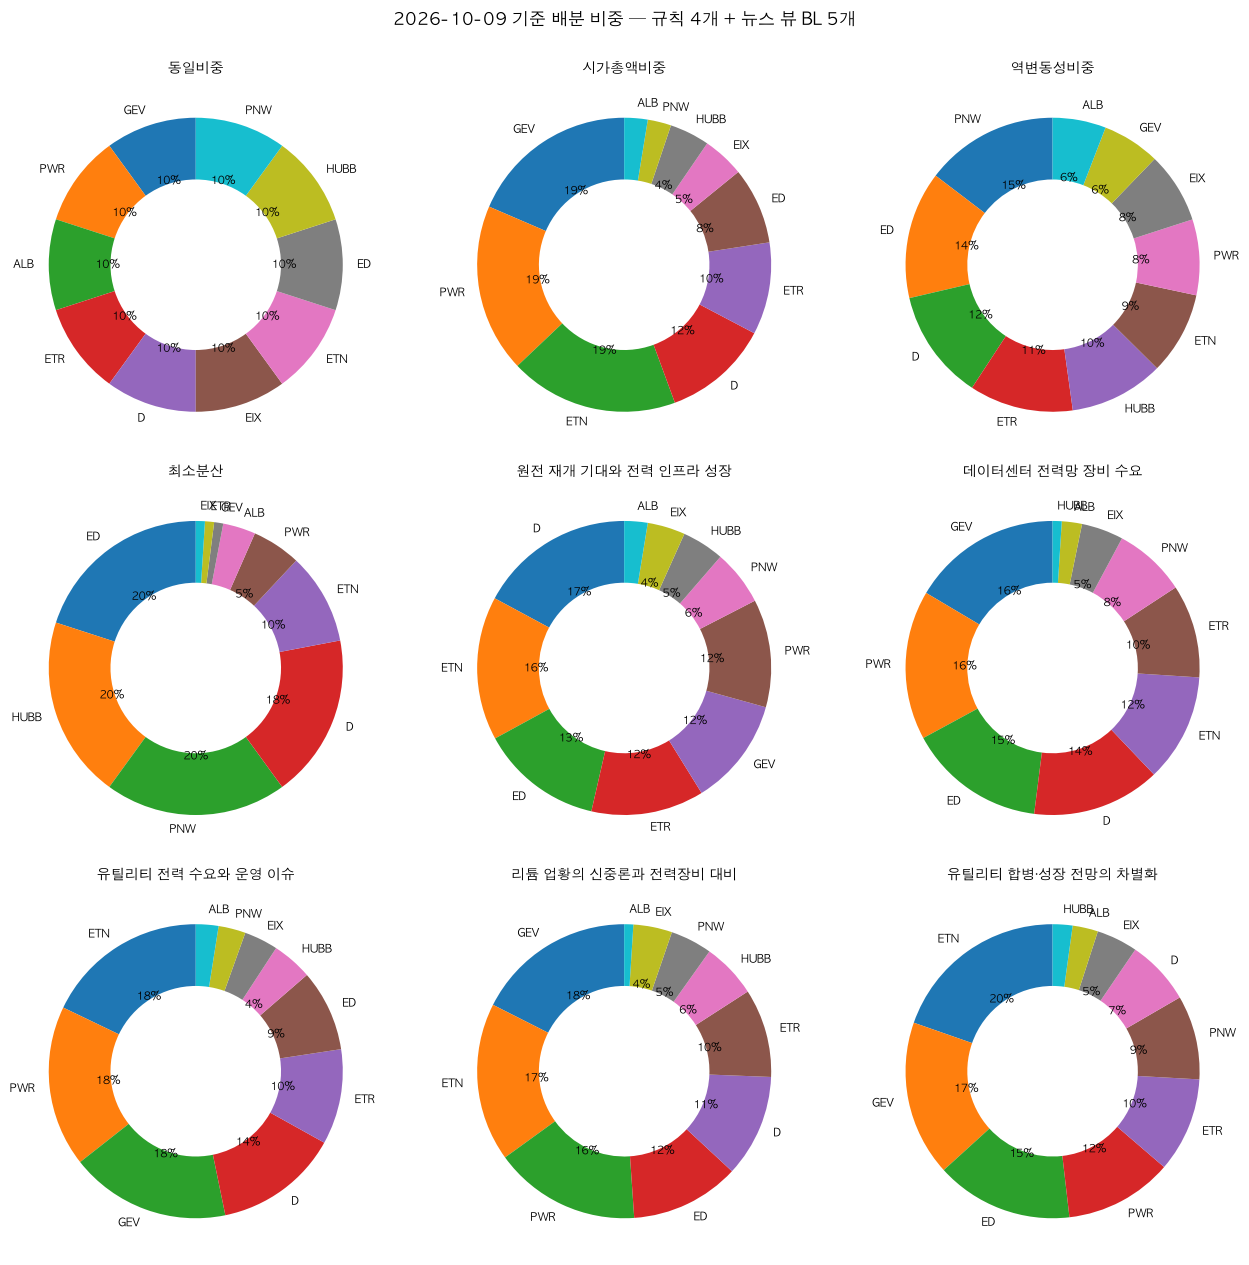

,비중,USD,원화
티커,,,
D,17.1%,"8,569.75","8,570"
ETN,15.8%,"7,907.50","7,908"
ED,13.5%,"6,732.60","6,733"
ETR,12.4%,"6,203.70","6,204"
GEV,11.9%,"5,934.65","5,935"
PWR,11.9%,"5,934.65","5,935"
PNW,6.1%,"3,040.00","3,040"
HUBB,4.6%,"2,319.75","2,320"
EIX,4.1%,"2,072.35","2,072"


In [14]:
F = R["portfolio"].get("forward")
if not F:
    print("현재 구성 결과 없음")
else:
    nw = F.get("news_window"); print(f"기준일 {F['as_of']} · 뉴스 창 {nw['window'][0]}~{nw['window'][1]} · 기사 {nw['n_articles']}건 · 뉴스 있는 종목 {nw['n_tickers_with_news']} · δ={F['market_model']['delta']} ({F['market_model']['delta_source']})" if nw else f"기준일 {F['as_of']}")
    sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0][:120], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                        "근거 수": len({i for v in p["views_applied"] for i in v.get("evidence_ids", [])}), "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in F["portfolios"]])
    display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
    ports = F["templates"] + F["portfolios"]
    cols = 3; rows_ = -(-len(ports) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(13, 4.2 * rows_))
    for ax, p in zip(axes.flat, ports):
        items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
        ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
        ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=10)
    for ax in list(axes.flat)[len(ports):]: ax.axis("off")
    plt.suptitle(f"{F['as_of']} 기준 배분 비중 — 규칙 4개 + 뉴스 뷰 BL {len(F['portfolios'])}개", y=1.0); plt.tight_layout(); plt.show()
    chosen = F["portfolios"][0] if F["portfolios"] else F["templates"][0]
    display(pd.DataFrame(chosen["allocation"]).rename(columns={"ticker": "티커", "weight": "비중", "usd": "USD", "krw": "원화"}).set_index("티커").style.format({"비중": "{:.1%}", "USD": "{:,.2f}", "원화": "{:,.0f}"}).set_caption(f"배분 금액 — {chosen['name_ko']} (투자금 {F['capital']['initial_amount_usd']:,.0f} USD)"))

## 7. 비용·조건·경고

In [15]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,1.000000,6536.000000,3026.000000,0.0026
04_classify,3.000000,6429.000000,11925.000000,0.0074
09_views,1.000000,2027.000000,3685.000000,0.0023
09n_wf_2026-10-01,1.000000,3335.000000,1723.000000,0.0016
09n_forward,1.000000,6264.000000,5426.000000,0.0041


,사용한 내용
출처,
팀 데이터베이스 price_daily,"일별 주가·수정주가·거래량 (여러 소스의 합의값 CONSENSUS 우선, 1종목·1일 1행)"
팀 데이터베이스 financials (SEC EDGAR),발행주식수 (시가총액 필터·시가총액 비중)
팀 데이터베이스 fx_daily,원/달러 환율 USDKRW (투자금 환산 기준일 종가)
Yahoo Finance (yfinance) 캐시 사본,비교지수 ETF (SPY·QQQ·XLV) — 팀 DB 미보유로 캐시 사본 사용
팀 데이터베이스 news,"종목 뉴스 헤드라인 (GOOGLE_RSS·NEWSAPI·NAVER_NEWS), 구성일 직전 14일 창"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(정적 뷰는 뉴스 미연결, walk-forward·현재 구성은 DB 뉴스 근거), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,02,theme renewable_energy: dropped tickers outside universe ['ENPH']
1,02,"theme nuclear_energy: dropped tickers outside universe ['BWXT', 'CCJ']"
2,12,alternative skipped: chosen portfolio already within the drawdown tolerance
3,data,"DB 동기화(2026-10-10T11:21:13): DB price_daily에 없는 유니버스 종목 3개: SKYD, TWLO, VYLR..."
4,data,DB 동기화(2026-10-10T11:21:13): 발행주식수가 DB(SEC_EDGAR)에 없는 종목 44개는 yfinance 캐시 값을 사용
5,data,DB 동기화(2026-10-10T11:21:13): 비교지수(SPY·QQQ·XLV 등)는 팀 DB에 없어 yfinance 캐시 사본을 사...
